# Project 3: Demand Forecasting and Inventory Planning (FreshMart)

**Folder:** `27_pandas/project/` | **Level:** Intermediate to Advanced | **Time:** 3 to 4 hours | **Libraries:** NumPy, pandas, Matplotlib (no scikit-learn needed)

## The business problem

FreshMart is a supermarket chain with 3 stores (Indore, Bhopal, Pune). Every day each store must decide **how many units** of each fresh product to stock (milk, curd, bread, eggs, tomato, onion, paneer, banana). The supplier needs **2 days notice**.

- Order **too little**: shelves are empty, the customer leaves (lost sale and lost goodwill).
- Order **too much**: perishable food is thrown away (waste).

Today the store manager uses a rule of thumb ("average of the same weekday in the last 3 weeks, plus a bit"). Result: sold-out days **and** waste at the same time.

> **How many units of each product should each store order, so that waste plus lost sales cost the least?**

This is the classic **newsvendor problem**, and it needs two things: a good **forecast** and a good **decision rule on top of the forecast**.

## What you will build

1. Read **four raw files** (sales, products, weather, events), clean them and rebuild a **complete daily calendar**
2. Handle the hardest real-world detail of sales data: **stock-outs hide the true demand** (you cannot sell what you do not have)
3. Engineer **calendar, festival, promotion, weather and lag features** using only information available 2 days earlier
4. Forecast with baselines and a **ridge regression written from scratch in NumPy** (with NumPy broadcasting for interactions)
5. Evaluate by **time**, with WAPE and bias, per product
6. Convert forecasts into **order quantities** with the newsvendor rule and measure waste and lost sales in rupees

## Skills map

| Skill | Where | Theory notebook |
|---|---|---|
| Messy dates, `drop_duplicates`, text flags, `to_numeric` | cleaning 4 files | 03, 08 |
| Outlier detection with rolling median (Hampel idea) | 10x typing mistakes | 08, 13 |
| `MultiIndex.from_product`, `merge(validate="one_to_one")`, `reindex`, `interpolate` | complete calendar, closed days | 07, 11, 13 |
| `groupby().shift()`, `rolling` per series, lags at lead time | forecasting features | 09, 13 |
| `pivot_table`, `cut`, `quantile`, `idxmin` | EDA, policy analysis | 10, 12 |
| NumPy: `einsum`-style broadcasting for interactions, `linalg.solve`, `quantile`, `minimum`, `maximum` | model and policy simulation | 26_numpy |
| Matplotlib: `axvspan`, `fill_between`, grouped bars, `imshow` heatmap | all charts | 15 |
| Time-based train/validation/test, leakage, baselines | split design, seasonal naive | 09, 13 |

---
# 0. Setup

In [1]:
import itertools
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

PROJECT = "project_3_retail_demand_forecasting"
DATA = Path("data") / PROJECT
FIG = Path("figures") / PROJECT
DATA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 21
LEAD_TIME = 2                      # days between ordering and delivery: the forecast for day t may only use data up to day t - 2

plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.6 | numpy 2.5.3


---
# 1. The raw data

As in the other projects, the files are **simulated** with a seed (reproducible), with real-world problems on purpose. The simulator generates the **true customer demand** each day (weekly pattern, trend, season, festivals, promotions, temperature, random noise) and then applies the **store manager's ordering rule**. What the stores record is **sales**, which is the true demand **capped by the stock on the shelf**.

> The simulator also returns the **true demand** (`truth`). In real life nobody knows it. We will use it **only once**, at the very end, to measure the real effect of ordering policies. (In real life you would run a pilot in a few stores.)

Festival dates in `events` are an approximate marketing calendar (simulated).

In [2]:
PRODUCTS = pd.DataFrame({'sku': ['MILK', 'CURD', 'BREAD', 'EGGS', 'TOMATO', 'ONION', 'PANEER', 'BANANA'], 'name': ['Milk 1L', 'Curd 400g', 'Bread', 'Eggs (12)', 'Tomato 1kg', 'Onion 1kg', 'Paneer 200g', 'Banana 1 dozen'], 'category': ['dairy', 'dairy', 'bakery', 'protein', 'vegetable', 'vegetable', 'dairy', 'fruit'], 'shelf_life_days': [2, 5, 3, 10, 5, 14, 5, 3], 'price': [56, 40, 45, 84, 40, 35, 110, 60], 'cost': [45, 28, 32, 66, 26, 25, 78, 38], 'salvage': [0.0, 0.0, 0.1, 0.5, 0.2, 0.8, 0.0, 0.3]})
BASE_DEMAND = {'MILK': 140, 'CURD': 70, 'BREAD': 90, 'EGGS': 110, 'TOMATO': 120, 'ONION': 130, 'PANEER': 40, 'BANANA': 100}
WEEKEND = {'MILK': 1.08, 'CURD': 1.12, 'BREAD': 1.22, 'EGGS': 1.1, 'TOMATO': 1.05, 'ONION': 1.02, 'PANEER': 1.35, 'BANANA': 1.18}
TEMP_SENS = {'MILK': 0.004, 'CURD': 0.02, 'BREAD': 0.0, 'EGGS': -0.003, 'TOMATO': -0.004, 'ONION': 0.0, 'PANEER': 0.0, 'BANANA': 0.012}
FIXED_HOLIDAYS = ['01-01', '01-26', '08-15', '10-02', '12-25']
FESTIVAL_WEEKS = [('Diwali week', '2024-10-28', '2024-11-03'), ('Diwali week', '2025-10-17', '2025-10-23')]
STORES = {'S1-Indore': (1.0, 0), 'S2-Bhopal': (0.8, 1), 'S3-Pune': (1.3, -2)}

def make_freshmart(seed=21):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2024-07-01", "2026-06-30", freq="D")
    T = len(dates)
    stores, skus = list(STORES), PRODUCTS["sku"].tolist()
    series = [(st, sk) for st in stores for sk in skus]
    S = len(series)
    size = np.array([STORES[st][0] for st, _ in series])
    base = np.array([BASE_DEMAND[sk] for _, sk in series]) * size

    doy = dates.dayofyear.to_numpy()
    dow = dates.dayofweek.to_numpy()
    weekend = np.array([[WEEKEND[sk] if d >= 5 else 1.0 for d in dow] for _, sk in series])               # S x T
    year_season = 1 + 0.06 * np.sin(2 * np.pi * (doy - 80) / 365.25)
    trend = 1 + 0.0003 * np.arange(T)
    payday = 1 + 0.08 * (dates.day.to_numpy() <= 7)
    is_hol = np.isin(dates.strftime("%m-%d"), FIXED_HOLIDAYS)
    fest = np.zeros(T, dtype=bool)
    for _, a, b in FESTIVAL_WEEKS:
        fest |= (dates >= a) & (dates <= b)
    fest_boost = np.array([1.35 if sk in ("PANEER", "BANANA") else 1.12 for _, sk in series])[:, None] ** fest[None, :]
    hol_boost = 1.08 ** is_hol[None, :]

    # weather per store city
    temp_base = 27 + 8 * np.sin(2 * np.pi * (doy - 110) / 365.25)
    temp = np.array([temp_base + STORES[st][1] + rng.normal(0, 1.5, T) for st, _ in series])
    temp_dev = temp - 27
    temp_eff = np.array([1 + TEMP_SENS[sk] * temp_dev[i] for i, (_, sk) in enumerate(series)])

    # promotions: planned in advance, price -15% and demand +30%
    promo = rng.random((S, T)) < 0.07
    price0 = np.array([PRODUCTS.set_index("sku").loc[sk, "price"] for _, sk in series], dtype=float)
    price = np.where(promo, price0[:, None] * 0.85, price0[:, None]).round(1)
    promo_eff = 1.30 ** promo

    mean_demand = base[:, None] * weekend * year_season[None, :] * trend[None, :] * payday[None, :] * fest_boost * hol_boost * temp_eff * promo_eff
    r = 25.0                                                                                          # overdispersion of the negative binomial
    demand = rng.negative_binomial(r, r / (r + mean_demand)).astype(float)

    # the store manager's ordering rule: 1.05 x average of the same weekday in the last 3 weeks (OBSERVED sales), plus noise
    stock = np.zeros((S, T)); sold = np.zeros((S, T))
    for t in range(T):
        if t < 21:
            planned = base * 1.2
        else:
            # empty shelves are visible to the manager: a sell-out day counts as 15% higher demand
            seen = np.where(sold[:, [t - 7, t - 14, t - 21]] >= stock[:, [t - 7, t - 14, t - 21]], 1.15, 1.0) * sold[:, [t - 7, t - 14, t - 21]]
            planned = 1.18 * seen.mean(axis=1)
        stock[:, t] = np.round(planned * rng.lognormal(0, 0.10, S))
        sold[:, t] = np.minimum(demand[:, t], stock[:, t])

    # ---------- observed (messy) tables ----------
    idx_s, idx_t = np.meshgrid(np.arange(S), np.arange(T), indexing="ij")
    sales = pd.DataFrame({
        "date": dates[idx_t.ravel()], "store_id": [series[i][0] for i in idx_s.ravel()],
        "sku": [series[i][1] for i in idx_s.ravel()],
        "units_sold": sold.ravel(), "stock_start": stock.ravel(), "price": price.ravel(),
        "promo_flag": promo.ravel(),
    })
    truth = sales[["date", "store_id", "sku"]].copy()
    truth["true_demand"] = demand.ravel()

    # closed days (all SKUs of a store missing)
    for st in stores:
        closed = rng.choice(dates, 5, replace=False)
        m = (sales["store_id"] == st) & sales["date"].isin(closed)
        sales, truth = sales[~m], truth[~m]
    sales = sales.reset_index(drop=True); truth = truth.reset_index(drop=True)

    # typos (x10), negative units (returns), mixed formats
    typo = rng.choice(len(sales), 25, replace=False)
    sales.loc[typo, "units_sold"] = sales.loc[typo, "units_sold"] * 10
    neg = rng.choice(len(sales), 12, replace=False)
    sales.loc[neg, "units_sold"] = -np.abs(sales.loc[neg, "units_sold"] // 10 + 1)
    fmt = rng.random(len(sales))
    sales["date"] = np.where(fmt < 0.9, sales["date"].dt.strftime("%Y-%m-%d"), sales["date"].dt.strftime("%d-%m-%Y"))
    sales["price"] = ["Rs. " + str(p) if rng.random() < 0.4 else str(p) for p in sales["price"]]
    sales["promo_flag"] = [rng.choice(["Y", "Yes", "1", "TRUE"]) if v else rng.choice(["N", "No", "0", "FALSE"]) for v in sales["promo_flag"]]
    sales = pd.concat([sales, sales.sample(30, random_state=5)], ignore_index=True)

    weather = pd.DataFrame({
        "date": np.tile(dates, len(stores)).tolist(),
        "store_id": np.repeat(stores, T),
        "temp_c": np.concatenate([temp[i * len(skus)] for i in range(len(stores))]).round(1),
        "rain_mm": np.where(rng.random(T * len(stores)) < 0.12, rng.gamma(1.5, 4, T * len(stores)), 0.0).round(1),
    })
    weather.loc[rng.random(len(weather)) < 0.02, "temp_c"] = np.nan
    weather["date"] = pd.to_datetime(weather["date"]).dt.strftime("%Y-%m-%d")

    events = pd.DataFrame(FESTIVAL_WEEKS, columns=["event", "start", "end"])
    return sales, PRODUCTS.copy(), weather, events, truth

In [3]:
sales_raw, products, weather_raw, events, truth = make_freshmart(seed=SEED)

sales_raw.to_csv(DATA / "sales_raw.csv", index=False)
products.to_csv(DATA / "products.csv", index=False)
weather_raw.to_csv(DATA / "weather_raw.csv", index=False)
events.to_csv(DATA / "events.csv", index=False)
truth.to_csv(DATA / "simulator_truth_DO_NOT_USE_FOR_MODELLING.csv", index=False)     # kept aside: only used in the final policy test

sales = pd.read_csv(DATA / "sales_raw.csv")
weather = pd.read_csv(DATA / "weather_raw.csv")
print("sales:", sales.shape, "| weather:", weather.shape, "| products:", products.shape, "| events:", events.shape)

sales: (17430, 7) | weather: (2190, 4) | products: (8, 7) | events: (2, 3)


## Data dictionary

| File | Column | Meaning |
|---|---|---|
| sales | `date`, `store_id`, `sku` | one row per store, product and day |
| | `units_sold` | units sold (**capped by stock!**) |
| | `stock_start` | units on the shelf at opening |
| | `price`, `promo_flag` | selling price, was there a promotion that day (planned in advance) |
| products | `price`, `cost`, `shelf_life_days`, `salvage` | selling price, buying cost, freshness, share of the cost recovered from unsold stock |
| weather | `date`, `store_id`, `temp_c`, `rain_mm` | daily weather per store city |
| events | `event`, `start`, `end` | big festival weeks (approximate) |

---
# 2. Look before you clean

In [4]:
sales.head()

,date,store_id,sku,units_sold,stock_start,price,promo_flag
0,2024-07-01,S1-Indore,MILK,145.0,188.0,56.0,N
1,2024-07-02,S1-Indore,MILK,158.0,158.0,Rs. 56.0,0
2,2024-07-03,S1-Indore,MILK,182.0,182.0,56.0,N
3,2024-07-04,S1-Indore,MILK,121.0,169.0,56.0,FALSE
4,2024-07-05,S1-Indore,MILK,158.0,158.0,Rs. 56.0,FALSE


In [5]:
def quick_look(df, name):
    print(f"--- {name}: {df.shape[0]} rows, {df.duplicated().sum()} exact duplicate rows ---")
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})

quick_look(sales, "sales")

--- sales: 17430 rows, 30 exact duplicate rows ---


,dtype,missing,unique
date,str,0,1402
store_id,str,0,3
sku,str,0,8
units_sold,float64,0,325
stock_start,float64,0,347
price,str,0,28
promo_flag,str,0,8


In [6]:
print("promo_flag spellings:", sales["promo_flag"].unique().tolist())
print("date text lengths   :", sales["date"].str.len().value_counts().to_dict(), "(10 characters in both formats: YYYY-MM-DD and DD-MM-YYYY)")
print("negative units      :", int((sales["units_sold"] < 0).sum()))
print("rows per store      :", sales.groupby("store_id").size().to_dict(), "| a full 730 days x 8 products would be", 730 * 8)
print(sales["units_sold"].describe().round(0))

promo_flag spellings: ['N', '0', 'FALSE', 'No', 'Yes', 'TRUE', 'Y', '1']
date text lengths   : {10: 17430} (10 characters in both formats: YYYY-MM-DD and DD-MM-YYYY)
negative units      : 12
rows per store      : {'S1-Indore': 5809, 'S2-Bhopal': 5815, 'S3-Pune': 5806} | a full 730 days x 8 products would be 5840
count    17430.0
mean       117.0
std         62.0
min        -23.0
25%         80.0
50%        112.0
75%        147.0
max       2210.0
Name: units_sold, dtype: float64


### Problems we found

| Problem | Fix |
|---|---|
| 30 duplicate rows | `drop_duplicates()` |
| `date` in two formats (`2025-03-05` and `05-03-2025`) | two-pass parsing |
| `price` as text (`Rs. 56.0`) | numeric |
| `promo_flag` spelled `Y`, `Yes`, `1`, `TRUE`, `N`, `No`... | map to 0/1 |
| Negative units (returns typed as sales) | NaN |
| Units 10x too big (typing mistake) | detect with a rolling median, set to NaN |
| A few days missing for **all** products of a store (store closed) | complete calendar, interpolate for lags |
| **Stock-outs**: `units_sold == stock_start` means the real demand was **at least** this | flag as *censored*, exclude from training targets |

**Say it in an interview:** "Sales are not demand. When a product sells out, the recorded sales are only a lower bound of the true demand (censored data). I flagged those days and kept them out of the training target."

---
# 3. Cleaning

In [7]:
log = []
def note(step, n):
    log.append({"step": step, "rows_or_values": int(n)})

s = sales.copy()

# 1. duplicates
before = len(s)
s = s.drop_duplicates().reset_index(drop=True)
note("exact duplicate rows removed", before - len(s))

# 2. dates (two-pass)
text = s["date"].str.strip()
iso = pd.to_datetime(text, format="ISO8601", errors="coerce")
other = pd.to_datetime(text.where(iso.isna()), format="%d-%m-%Y", errors="coerce")
s["date"] = iso.fillna(other)
note("dates parsed from DD-MM-YYYY", iso.isna().sum())
assert s["date"].notna().all()

# 3. price and promotion flag
# "Rs. 56.0": removing every non-digit except the dot would leave ".56.0" (the dot of "Rs." survives), so we EXTRACT the number instead
s["price"] = pd.to_numeric(s["price"].str.extract(r"(\d+\.?\d*)", expand=False))
flag_map = {"y": 1, "yes": 1, "1": 1, "true": 1, "n": 0, "no": 0, "0": 0, "false": 0}
s["promo"] = s["promo_flag"].str.strip().str.lower().map(flag_map)
assert s["promo"].notna().all()
s["promo"] = s["promo"].astype(int)
s = s.drop(columns="promo_flag")

# 4. keys
s["series"] = s["store_id"] + "|" + s["sku"]
assert not s.duplicated(["series", "date"]).any()

# 5. negative units
neg = s["units_sold"] < 0
s.loc[neg, "units_sold"] = np.nan
note("negative units -> NaN", neg.sum())

# 6. typing mistakes: a value more than 3x the rolling median of its own product/store (centered 15-day window)
s = s.sort_values(["series", "date"]).reset_index(drop=True)
med = s.groupby("series")["units_sold"].transform(lambda x: x.rolling(15, center=True, min_periods=5).median())
typo = (s["units_sold"] > 3 * med) & (s["units_sold"] - med > 40)
note("suspicious spikes (> 3x rolling median) -> NaN", typo.sum())
spikes_example = s.loc[typo, ["series", "date", "units_sold"]].head(3).assign(rolling_median=med[typo].head(3).round(0))
s.loc[typo, "units_sold"] = np.nan

# ---- weather and events ----
w = weather.copy()
w["date"] = pd.to_datetime(w["date"])
w["temp_c"] = w.groupby("store_id")["temp_c"].transform(lambda x: x.interpolate(limit_direction="both"))
note("missing temperatures interpolated", weather["temp_c"].isna().sum())

ev = events.assign(start=pd.to_datetime(events["start"]), end=pd.to_datetime(events["end"]))

print(pd.DataFrame(log).to_string(index=False))
print("\nexamples of detected spikes:")
spikes_example

                                          step  rows_or_values
                  exact duplicate rows removed              30
                  dates parsed from DD-MM-YYYY            1733
                         negative units -> NaN              12
suspicious spikes (> 3x rolling median) -> NaN              25
             missing temperatures interpolated              47

examples of detected spikes:


,series,date,units_sold,rolling_median
41,S1-Indore|BANANA,2024-08-11,1170.0,120.0
1492,S1-Indore|CURD,2024-08-12,860.0,99.0
4531,S1-Indore|PANEER,2024-12-29,720.0,41.0


## 3.2 Rebuild a complete daily calendar (chapter 11 and 13)

Lags and rolling windows count **rows**. If days are missing (store closed), "7 rows back" is no longer "7 days back". So we create **one row per product, store and day** with `MultiIndex.from_product`, and merge the sales onto it (`validate="one_to_one"` proves nothing is duplicated).

In [8]:
dates_all = pd.date_range(s["date"].min(), s["date"].max(), freq="D")
series_ids = sorted(s["series"].unique())

grid = pd.MultiIndex.from_product([series_ids, dates_all], names=["series", "date"]).to_frame(index=False)
df = grid.merge(s[["series", "date", "units_sold", "stock_start", "price", "promo"]], on=["series", "date"], how="left", validate="one_to_one")
df[["store_id", "sku"]] = df["series"].str.split("|", expand=True)

print("series:", len(series_ids), "| days:", len(dates_all), "| rows:", len(df))
print("rows without a record (closed days + removed bad values):", int(df["units_sold"].isna().sum()))

# attach weather (many rows per store and day -> one weather row)
df = df.merge(w[["store_id", "date", "temp_c", "rain_mm"]], on=["store_id", "date"], how="left", validate="many_to_one")
assert len(df) == len(grid)

# fill what is known for sure for missing rows: the normal price and no promotion
base_price = products.set_index("sku")["price"]
df["price"] = df["price"].fillna(df["sku"].map(base_price))
df["promo"] = df["promo"].fillna(0).astype(int)

# calendar flags
HOLIDAYS = ["01-01", "01-26", "08-15", "10-02", "12-25"]
df["holiday"] = df["date"].dt.strftime("%m-%d").isin(HOLIDAYS).astype(int)
df["festival"] = 0
for _, e in ev.iterrows():
    df.loc[df["date"].between(e["start"], e["end"]), "festival"] = 1

# demand signals
df["censored"] = (df["units_sold"] >= df["stock_start"]) & df["stock_start"].notna()       # sold out: demand was AT LEAST this
df["observed"] = df["units_sold"].notna()
df["units_filled"] = df.groupby("series")["units_sold"].transform(lambda x: x.interpolate(limit=7, limit_direction="both"))

stock_rate = df[df["observed"]].groupby("sku")["censored"].mean().mul(100).round(1)
print("\nshare of days with a stock-out (sold out), by product (%):")
print(stock_rate.to_dict())

series: 24 | days: 730 | rows: 17520
rows without a record (closed days + removed bad values): 157

share of days with a stock-out (sold out), by product (%):
{'BANANA': 29.4, 'BREAD': 30.5, 'CURD': 30.5, 'EGGS': 28.8, 'MILK': 28.4, 'ONION': 27.6, 'PANEER': 31.5, 'TOMATO': 28.3}


**Why does the stock-out rate matter so much?** Imagine a product that sells out at 4 pm every Saturday with 120 units sold. The recorded sales say "120", but real demand might be 150. A model trained naively on these numbers **learns to under-order**, and the under-ordering creates more sold-out days: a **vicious circle**. We will not train on the censored days.

# 4. Exploratory analysis (training period only)

In [9]:
TEST_DAYS, VALID_DAYS = 84, 56
test_start = dates_all.max() - pd.Timedelta(days=TEST_DAYS - 1)           # last 12 weeks
valid_start = test_start - pd.Timedelta(days=VALID_DAYS)                  # the 8 weeks before
train_end = valid_start - pd.Timedelta(days=1)
print("train until", train_end.date(), "| validation", valid_start.date(), "to", (test_start - pd.Timedelta(days=1)).date(), "| test", test_start.date(), "to", dates_all.max().date())

eda = df[(df["date"] <= train_end) & df["observed"] & ~df["censored"]].copy()
eda["level"] = eda.groupby("series")["units_sold"].transform("mean")
eda["index"] = eda["units_sold"] / eda["level"]                     # 1.0 = this product's normal day

train until 2026-02-10 | validation 2026-02-11 to 2026-04-07 | test 2026-04-08 to 2026-06-30


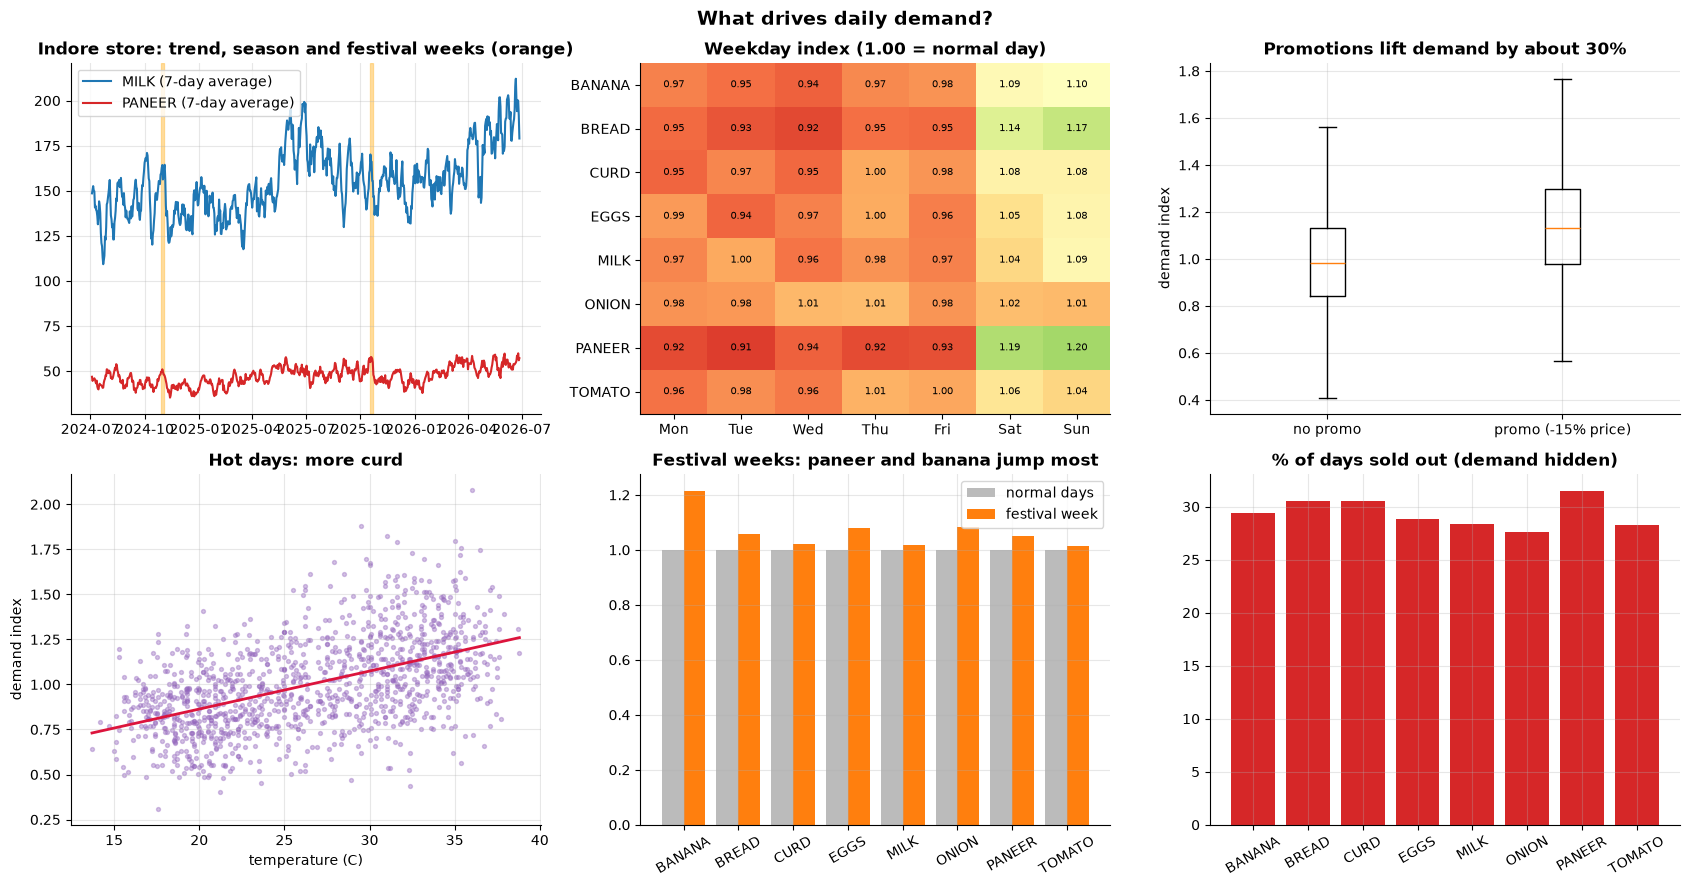

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# 1. two series with the festival weeks shaded
for sku, color in [("MILK", "#1f77b4"), ("PANEER", "#d62728")]:
    x = df[(df["series"] == f"S1-Indore|{sku}")].set_index("date")["units_filled"]
    axes[0, 0].plot(x.index, x.rolling(7, center=True).mean(), color=color, label=f"{sku} (7-day average)")
for _, e in ev.iterrows():
    axes[0, 0].axvspan(e["start"], e["end"], color="orange", alpha=0.35)
axes[0, 0].set_title("Indore store: trend, season and festival weeks (orange)"); axes[0, 0].legend()

# 2. weekday pattern per product (index vs the product's normal day)
dow = eda.pivot_table(index="sku", columns=eda["date"].dt.dayofweek, values="index", aggfunc="mean")
im = axes[0, 1].imshow(dow.to_numpy(), cmap="RdYlGn", aspect="auto", vmin=0.85, vmax=1.35)
axes[0, 1].set_xticks(range(7)); axes[0, 1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0, 1].set_yticks(range(len(dow))); axes[0, 1].set_yticklabels(dow.index)
for i in range(dow.shape[0]):
    for j in range(7):
        axes[0, 1].text(j, i, f"{dow.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[0, 1].grid(False); axes[0, 1].set_title("Weekday index (1.00 = normal day)")

# 3. promotion effect
promo_groups = [eda.loc[eda["promo"] == 0, "index"], eda.loc[eda["promo"] == 1, "index"]]
axes[0, 2].boxplot(promo_groups, tick_labels=["no promo", "promo (-15% price)"], showfliers=False)
axes[0, 2].set_title("Promotions lift demand by about 30%"); axes[0, 2].set_ylabel("demand index")

# 4. temperature and curd
curd = eda[eda["sku"] == "CURD"]
axes[1, 0].scatter(curd["temp_c"], curd["index"], s=8, alpha=0.4, color="#9467bd")
coef = np.polyfit(curd["temp_c"], curd["index"], 1)
xs = np.linspace(curd["temp_c"].min(), curd["temp_c"].max(), 50)
axes[1, 0].plot(xs, np.polyval(coef, xs), color="crimson", linewidth=2)
axes[1, 0].set_title("Hot days: more curd"); axes[1, 0].set_xlabel("temperature (C)"); axes[1, 0].set_ylabel("demand index")

# 5. festival lift by product
fest = eda.groupby(["sku", "festival"])["index"].mean().unstack()
x = np.arange(len(fest))
axes[1, 1].bar(x - 0.2, fest[0], width=0.4, label="normal days", color="#bbbbbb")
axes[1, 1].bar(x + 0.2, fest[1], width=0.4, label="festival week", color="#ff7f0e")
axes[1, 1].set_xticks(x); axes[1, 1].set_xticklabels(fest.index, rotation=30); axes[1, 1].legend()
axes[1, 1].set_title("Festival weeks: paneer and banana jump most")

# 6. stock-outs
axes[1, 2].bar(stock_rate.index, stock_rate.values, color="#d62728")
axes[1, 2].set_title("% of days sold out (demand hidden)"); axes[1, 2].tick_params(axis="x", rotation=30)

fig.suptitle("What drives daily demand?", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()
savefig(fig, "01_eda_demand_drivers")

**What we learned:** a weekly pattern that differs by product (paneer and bread at weekends), a **long-term trend and a yearly season**, **festival** weeks, **promotions** (about +30%), **temperature** (curd), and about a quarter of the days are **sold out**. All of these become features. Everything is available **in advance** (calendar, planned promotion, weather forecast).

# 5. Feature engineering

**The rule of this project:** the forecast for day `t` is made on day `t - 2`, so **every demand feature must be shifted by at least 2 days**. Lags of 2, 7, 14, 21 and 28 days and rolling averages that end 2 days before the target.

In [11]:
df = df.sort_values(["series", "date"]).reset_index(drop=True)
g = df.groupby("series")["units_filled"]

for k in [LEAD_TIME, 7, 14, 21, 28]:
    df[f"lag_{k}"] = g.shift(k)
df["same_dow_mean"] = df[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)          # same weekday, last 4 weeks
df["roll7"] = g.transform(lambda x: x.shift(LEAD_TIME).rolling(7).mean())
df["roll28"] = g.transform(lambda x: x.shift(LEAD_TIME).rolling(28).mean())

# calendar and context features (all known in advance)
d = df["date"].dt
df["dow"] = d.dayofweek
df["doy_sin"] = np.sin(2 * np.pi * d.dayofyear / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * d.dayofyear / 365.25)
df["payday_week"] = (d.day <= 7).astype(int)
df["month_end"] = d.is_month_end.astype(int)
df["trend"] = (df["date"] - dates_all.min()).dt.days / 365
df["price_ratio"] = df["price"] / df["sku"].map(base_price)
df["temp_dev"] = df["temp_c"] - 27

# leakage guard: the most recent day used by lag_2 is exactly 2 days before the target day
check = df[df["series"] == series_ids[0]].set_index("date")
assert check["lag_2"].iloc[10] == check["units_filled"].iloc[8]
assert check["roll7"].iloc[40] == check["units_filled"].iloc[32:39].mean()         # days t-8 ... t-2
print("lags and rolling windows end 2 days before the target: OK")

df[["series", "date", "units_sold", "lag_2", "lag_7", "same_dow_mean", "roll7", "roll28"]].iloc[100:105].round({"same_dow_mean": 1, "roll7": 1, "roll28": 1})

lags and rolling windows end 2 days before the target: OK


,series,date,units_sold,lag_2,lag_7,same_dow_mean,roll7,roll28
100,S1-Indore|BANANA,2024-10-09,129.0,129.0,113.0,117.0,119.6,117.4
101,S1-Indore|BANANA,2024-10-10,71.0,106.0,90.0,84.8,116.0,116.6
102,S1-Indore|BANANA,2024-10-11,74.0,129.0,120.0,123.0,118.3,117.4
103,S1-Indore|BANANA,2024-10-12,93.0,71.0,109.0,142.0,115.6,117.5
104,S1-Indore|BANANA,2024-10-13,113.0,74.0,145.0,123.0,109.0,116.3


## 5.2 The split by time

- **Train:** everything before the validation period (the first 28 days of every series have no lags and are dropped)
- **Validation (8 weeks):** choose the ridge strength
- **Test (12 weeks):** touched once

For modelling and for the accuracy metrics we keep only days with an **observed, not sold-out** demand.

In [12]:
usable = df[df["observed"] & ~df["censored"] & df[["lag_28", "roll28"]].notna().all(axis=1)].copy()

train = usable[usable["date"] <= train_end]
valid = usable[(usable["date"] >= valid_start) & (usable["date"] < test_start)]
test = usable[usable["date"] >= test_start]

pd.DataFrame({"rows": [len(train), len(valid), len(test)],
              "from": [x["date"].min().date() for x in (train, valid, test)],
              "to": [x["date"].max().date() for x in (train, valid, test)]}, index=["train", "validation", "test"])

,rows,from,to
train,9513,2024-07-30,2026-02-10
validation,884,2026-02-11,2026-04-07
test,1442,2026-04-08,2026-06-30


## 5.3 The design matrix, with NumPy broadcasting for interactions

Products behave differently: paneer reacts to the weekend more than onion, curd reacts to temperature, and so on. A single linear model can learn this if we give it **interaction columns** such as `PANEER x Saturday`. With NumPy broadcasting we build them without any loop over rows:

```
sku_onehot[:, :, None] * dow_onehot[:, None, :]   ->   shape (rows, 8 products, 7 weekdays)  ->  reshape (rows, 56)
```

In [13]:
SKUS = sorted(df["sku"].unique())
STORES = sorted(df["store_id"].unique())

def onehot(series, categories):
    return np.column_stack([(series.to_numpy() == c).astype(float) for c in categories])

def cross(A, B, names_a, names_b):
    """All pairwise products of the columns of A and B, built with broadcasting."""
    out = (A[:, :, None] * B[:, None, :]).reshape(len(A), -1)
    names = [f"{a} x {b}" for a, b in itertools.product(names_a, names_b)]
    return out, names

def build_X(d):
    cols, names = [], []

    # 1. demand history on the log scale
    for c in ["lag_2", "lag_7", "lag_14", "lag_21", "lag_28", "same_dow_mean", "roll7", "roll28"]:
        cols.append(np.log1p(d[c].to_numpy())[:, None]); names.append(c)

    # 2. calendar / context (one column each)
    simple = ["doy_sin", "doy_cos", "payday_week", "month_end", "holiday", "festival", "promo", "price_ratio", "temp_dev", "trend"]
    for c in simple:
        cols.append(d[c].to_numpy(float)[:, None]); names.append(c)

    # 3. categories and interactions
    sku, dow, store = onehot(d["sku"], SKUS), onehot(d["dow"], range(7)), onehot(d["store_id"], STORES)
    for block, nm in [(sku, SKUS), (store, STORES)]:
        cols.append(block); names += nm
    for vec_name in ["promo", "festival", "temp_dev"]:
        block, nm = cross(sku, d[vec_name].to_numpy(float)[:, None], SKUS, [vec_name])
        cols.append(block); names += nm
    block, nm = cross(sku, dow, SKUS, [f"dow{i}" for i in range(7)])
    cols.append(block); names += nm

    return np.hstack(cols), names

Xtr, feature_names = build_X(train)
Xva, _ = build_X(valid)
Xte, _ = build_X(test)

# standardise with TRAIN statistics only
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
sd[sd == 0] = 1.0
Xtr, Xva, Xte = [(X - mu) / sd for X in (Xtr, Xva, Xte)]

ytr, yva, yte = (np.log1p(x["units_sold"].to_numpy()) for x in (train, valid, test))
print("design matrices:", Xtr.shape, Xva.shape, Xte.shape, "|", len(feature_names), "features")
print("examples:", [feature_names[i] for i in [0, 12, 20, 40, 60, 100]])

design matrices: (9513, 109) (884, 109) (1442, 109) | 109 features
examples: ['lag_2', 'holiday', 'CURD', 'EGGS x festival', 'BREAD x dow0', 'PANEER x dow5']


---
# 6. Forecast models

## 6.1 Metrics for demand forecasting

| Metric | Formula | Meaning |
|---|---|---|
| **WAPE** | `sum(abs(error)) / sum(actual)` | the total error as a share of the total demand. Works when some days are small (MAPE explodes) |
| **Bias** | `sum(forecast - actual) / sum(actual)` | positive = we over-forecast on average (waste), negative = under-forecast (stock-outs) |
| MAE | mean absolute error in units | |

In [14]:
def forecast_metrics(actual, forecast):
    err = forecast - actual
    return {"WAPE %": np.abs(err).sum() / actual.sum() * 100, "bias %": err.sum() / actual.sum() * 100, "MAE (units)": np.abs(err).mean()}

# Baselines (these need no learning)
def baselines(d):
    return {
        "naive: demand 2 days ago": d["lag_2"],
        "seasonal naive: same weekday last week": d["lag_7"],
        "same weekday, mean of 4 weeks": d["same_dow_mean"],
        "moving average 28 days": d["roll28"],
    }

rows = {name: forecast_metrics(valid["units_sold"], pred) for name, pred in baselines(valid).items()}
pd.DataFrame(rows).T.round(2)

,WAPE %,bias %,MAE (units)
naive: demand 2 days ago,22.56,3.70,26.01
seasonal naive: same weekday last week,20.47,6.73,23.59
"same weekday, mean of 4 weeks",16.36,3.96,18.85
moving average 28 days,16.08,2.62,18.53


## 6.2 Ridge regression from scratch (on the log of demand)

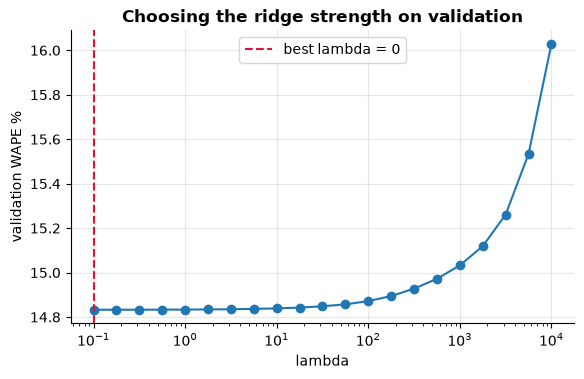

In [15]:
class RidgeScratch:
    def __init__(self, lam=1.0):
        self.lam = lam

    def fit(self, X, y):
        self.y_mean = y.mean()
        A = X.T @ X + self.lam * np.eye(X.shape[1])
        self.w = np.linalg.solve(A, X.T @ (y - self.y_mean))
        return self

    def predict(self, X):
        return X @ self.w + self.y_mean

lams = np.logspace(-1, 4, 21)
val_wape = []
for lam in lams:
    pred = np.expm1(RidgeScratch(lam).fit(Xtr, ytr).predict(Xva))
    val_wape.append(forecast_metrics(valid["units_sold"].to_numpy(), pred)["WAPE %"])
best_lam = lams[int(np.argmin(val_wape))]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(lams, val_wape, marker="o")
ax.axvline(best_lam, color="crimson", linestyle="--", label=f"best lambda = {best_lam:.0f}")
ax.set_xlabel("lambda"); ax.set_ylabel("validation WAPE %"); ax.set_title("Choosing the ridge strength on validation"); ax.legend()
plt.show()
savefig(fig, "02_lambda_validation")

In [16]:
ridge = RidgeScratch(best_lam).fit(Xtr, ytr)
pred_valid = np.expm1(ridge.predict(Xva))
rows["ridge regression (log target)"] = forecast_metrics(valid["units_sold"].to_numpy(), pred_valid)
pd.DataFrame(rows).T.round(2)

,WAPE %,bias %,MAE (units)
naive: demand 2 days ago,22.56,3.70,26.01
seasonal naive: same weekday last week,20.47,6.73,23.59
"same weekday, mean of 4 weeks",16.36,3.96,18.85
moving average 28 days,16.08,2.62,18.53
ridge regression (log target),14.83,-0.28,17.10


## 6.3 Fix the censoring bias (sold-out days)

So far the model learned only from days that did **not** sell out. Those days are, on average, the **low-demand** days, so the model learns a demand level that is **too low** (the vicious circle from section 3).

A simple, practical fix (one step of an "expectation-maximisation" idea):

1. Ask model v1 what it expects on the **sold-out** days.
2. We know the real demand was **at least** the recorded sales, so use `max(recorded sales, v1 forecast)` as the demand estimate for those days.
3. **Refit on all days** with the adjusted target (model v2).

In [17]:
def fit_scaler(X):
    mu, sd = X.mean(axis=0), X.std(axis=0)
    sd[sd == 0] = 1.0
    return mu, sd

# ALL usable rows, including the sold-out days
usable_all = df[df["observed"] & df[["lag_28", "roll28"]].notna().all(axis=1)].copy()
train_all = usable_all[usable_all["date"] <= train_end]
valid_all = usable_all[(usable_all["date"] >= valid_start) & (usable_all["date"] < test_start)]

# Step 1: what does model v1 expect on the days that sold out?
p1_train_all = np.expm1(ridge.predict((build_X(train_all)[0] - mu) / sd))
sold_out = train_all["censored"].to_numpy()
recorded = train_all["units_sold"].to_numpy()
print(f"sold-out days: {sold_out.sum()} | average recorded sales {recorded[sold_out].mean():.1f} | model v1 forecast {p1_train_all[sold_out].mean():.1f}")
print(f"on {np.mean(p1_train_all[sold_out] > recorded[sold_out]) * 100:.0f}% of the sold-out days the forecast is ABOVE the recorded sales (so the sales really were capped)")

# Step 2 and 3: adjusted target, refit on all days
y_adj_train = np.where(sold_out, np.maximum(recorded, p1_train_all), recorded)
mu_a, sd_a = fit_scaler(build_X(train_all)[0])
ridge2 = RidgeScratch(best_lam).fit((build_X(train_all)[0] - mu_a) / sd_a, np.log1p(y_adj_train))
pred_valid2_all = np.expm1(ridge2.predict((build_X(valid_all)[0] - mu_a) / sd_a))

# compare on the same validation days as before (the days that did not sell out)
same_rows = ~valid_all["censored"].to_numpy()
assert (valid_all.index[same_rows] == valid.index).all()
rows["ridge v2 (sold-out days imputed)"] = forecast_metrics(valid["units_sold"].to_numpy(), pred_valid2_all[same_rows])
pd.DataFrame(rows).T.round(2)

sold-out days: 3827 | average recorded sales 122.7 | model v1 forecast 104.3
on 10% of the sold-out days the forecast is ABOVE the recorded sales (so the sales really were capped)


,WAPE %,bias %,MAE (units)
naive: demand 2 days ago,22.56,3.70,26.01
seasonal naive: same weekday last week,20.47,6.73,23.59
"same weekday, mean of 4 weeks",16.36,3.96,18.85
moving average 28 days,16.08,2.62,18.53
ridge regression (log target),14.83,-0.28,17.10
ridge v2 (sold-out days imputed),15.02,4.12,17.31


Measured **only on days that did not sell out**, v2 looks slightly worse and **positively biased**. That is expected: those days are exactly the lower-demand days v1 was trained on. The correct test of v2 is against the **true demand** on all days, which we do in section 8. (In real life you cannot see that number, which is why censoring is dangerous.)

## 6.4 Final models (refit on train + validation) and the honest test

In [18]:
trval = usable[usable["date"] < test_start]                 # days that did not sell out (for model v1)
trval_all = usable_all[usable_all["date"] < test_start]     # all days (for model v2)

# model v1: only days that did not sell out
mu1, sd1 = fit_scaler(build_X(trval)[0])
final_v1 = RidgeScratch(best_lam).fit((build_X(trval)[0] - mu1) / sd1, np.log1p(trval["units_sold"].to_numpy()))

# model v2: v1 expectation replaces the recorded sales on sold-out days, then refit on all days
Xall_tv = build_X(trval_all)[0]
p1_all = np.expm1(final_v1.predict((Xall_tv - mu1) / sd1))
rec = trval_all["units_sold"].to_numpy()
y_adj = np.where(trval_all["censored"].to_numpy(), np.maximum(rec, p1_all), rec)
mu2, sd2 = fit_scaler(Xall_tv)
final_v2 = RidgeScratch(best_lam).fit((Xall_tv - mu2) / sd2, np.log1p(y_adj))

Xte = build_X(test)[0]
test = test.assign(forecast_v1=np.expm1(final_v1.predict((Xte - mu1) / sd1)),
                   forecast=np.expm1(final_v2.predict((Xte - mu2) / sd2)))

result = {name: forecast_metrics(test["units_sold"], pred) for name, pred in baselines(test).items()}
result["ridge v1 (ignores sold-out days)"] = forecast_metrics(test["units_sold"].to_numpy(), test["forecast_v1"].to_numpy())
result["RIDGE v2 (final)"] = forecast_metrics(test["units_sold"].to_numpy(), test["forecast"].to_numpy())
result = pd.DataFrame(result).T.round(2)
result

,WAPE %,bias %,MAE (units)
naive: demand 2 days ago,23.17,3.72,30.06
seasonal naive: same weekday last week,20.15,6.10,26.14
"same weekday, mean of 4 weeks",15.86,3.88,20.58
moving average 28 days,16.19,2.52,21.00
ridge v1 (ignores sold-out days),14.72,-2.14,19.09
RIDGE v2 (final),14.68,2.09,19.04


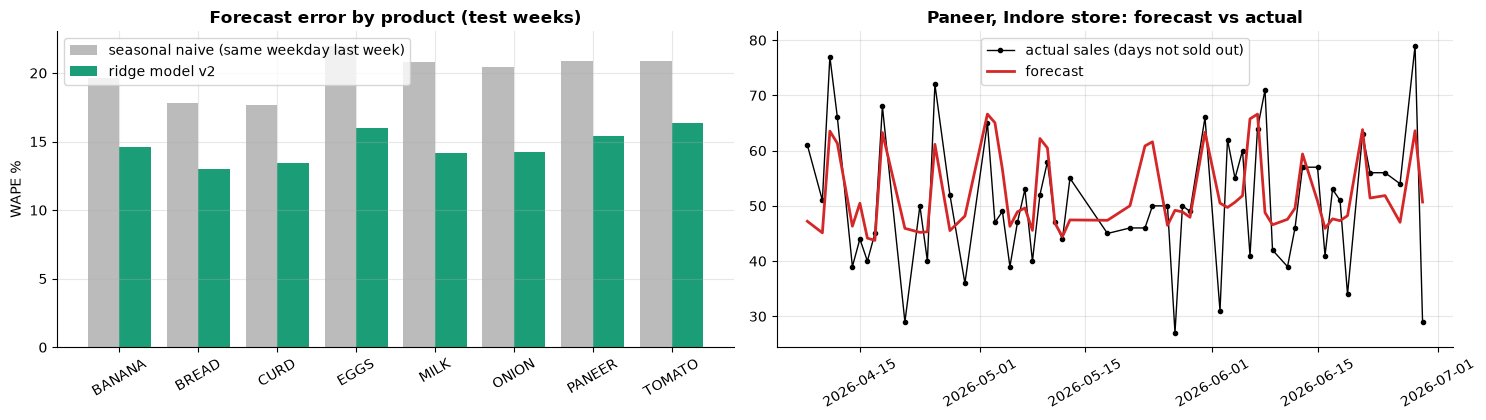

In [19]:
# WAPE by product: seasonal naive vs the model (days that did not sell out)
by_sku = test.assign(naive_err=(test["lag_7"] - test["units_sold"]).abs(), model_err=(test["forecast"] - test["units_sold"]).abs()) \
             .groupby("sku").agg(naive=("naive_err", "sum"), model=("model_err", "sum"), demand=("units_sold", "sum"))
wape_sku = pd.DataFrame({"seasonal naive": by_sku["naive"] / by_sku["demand"] * 100, "ridge model": by_sku["model"] / by_sku["demand"] * 100})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
x = np.arange(len(wape_sku))
axes[0].bar(x - 0.2, wape_sku["seasonal naive"], width=0.4, color="#bbbbbb", label="seasonal naive (same weekday last week)")
axes[0].bar(x + 0.2, wape_sku["ridge model"], width=0.4, color="#1b9e77", label="ridge model v2")
axes[0].set_xticks(x); axes[0].set_xticklabels(wape_sku.index, rotation=30); axes[0].set_ylabel("WAPE %"); axes[0].legend()
axes[0].set_title("Forecast error by product (test weeks)")

one = test[test["series"] == "S1-Indore|PANEER"].set_index("date")
axes[1].plot(one.index, one["units_sold"], color="black", marker="o", markersize=3, linewidth=1, label="actual sales (days not sold out)")
axes[1].plot(one.index, one["forecast"], color="#d62728", linewidth=2, label="forecast")
axes[1].set_title("Paneer, Indore store: forecast vs actual"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
savefig(fig, "03_forecast_quality")

**Say it in an interview:** "I compared the model with seasonal-naive and moving-average baselines, used WAPE and bias because demand has small values, split by time, and made every feature respect the 2-day order lead time. Interactions between product and weekday, promotion, festival and temperature were built with NumPy broadcasting. I also corrected the bias that sold-out days create."

# 7. Uncertainty: how wrong can the forecast be?

A forecast is a **guess**. To decide how much to order we need to know **how wrong** it typically is. We measure this on the **validation** period, as the ratio `actual / forecast`, per product. Its quantiles tell us: "to be covered 80% of the time, order the forecast times this factor".

For sold-out days the real demand is unknown but at least the sales, so we use the same adjusted demand as in section 6.3.

In [20]:
# v2 ratios on ALL validation days (adjusted demand on sold-out days)
y_adj_valid = np.where(valid_all["censored"].to_numpy(), np.maximum(valid_all["units_sold"].to_numpy(), pred_valid2_all), valid_all["units_sold"].to_numpy())
ratio_by_sku = pd.Series(y_adj_valid / pred_valid2_all, index=valid_all.index).groupby(valid_all["sku"].to_numpy())

# v1 ratios (days that did not sell out only), kept for the comparison in section 8
ratio_by_sku_v1 = pd.Series(valid["units_sold"].to_numpy() / pred_valid, index=valid.index).groupby(valid["sku"].to_numpy())

levels = np.array([0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99])
factors = pd.DataFrame({q: ratio_by_sku.quantile(q) for q in levels})
factors.columns = [f"q{int(q * 100)}" for q in levels]
factors.round(3)

,q50,q60,q70,q80,q90,q95,q99
BANANA,1.001,1.037,1.076,1.122,1.183,1.231,1.321
BREAD,1.048,1.072,1.105,1.169,1.222,1.299,1.406
CURD,1.018,1.044,1.077,1.134,1.208,1.229,1.374
EGGS,1.000,1.028,1.078,1.119,1.219,1.273,1.390
MILK,1.054,1.093,1.134,1.181,1.251,1.285,1.342
ONION,1.040,1.073,1.107,1.137,1.214,1.226,1.336
PANEER,1.009,1.053,1.109,1.172,1.244,1.321,1.479
TOMATO,1.012,1.047,1.082,1.145,1.221,1.270,1.348


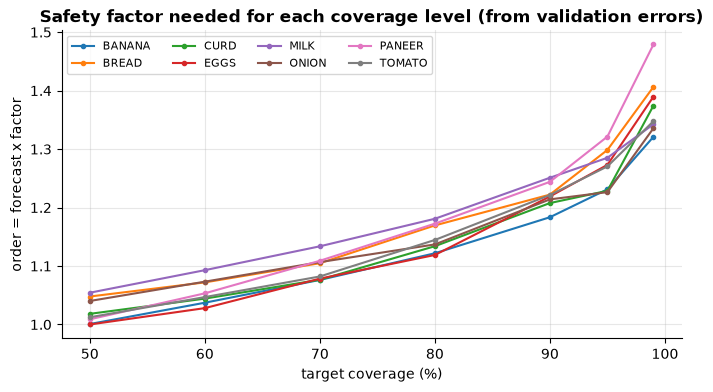

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for sku in SKUS:
    ax.plot(levels * 100, factors.loc[sku], marker="o", markersize=3, label=sku)
ax.set_xlabel("target coverage (%)"); ax.set_ylabel("order = forecast x factor")
ax.set_title("Safety factor needed for each coverage level (from validation errors)")
ax.legend(ncol=4, fontsize=8)
plt.show()
savefig(fig, "04_safety_factors")

---
# 8. From forecast to order quantity: the newsvendor rule

For each unit we order, there are two ways to be wrong:

| | Meaning | Cost per unit |
|---|---|---|
| **Underage** (stock-out) | one unit of demand we could not serve | lost margin `(price - cost)` **plus goodwill** (the unhappy customer, here 50% of the price) |
| **Overage** (waste) | one unit we threw away | `cost x (1 - salvage)` (what we cannot recover) |

The **cost-minimising order** is the demand quantile at the **critical ratio**:

```
critical ratio = underage cost / (underage cost + overage cost)
order quantity = demand quantile at that ratio   ->   forecast x (the matching safety factor)
```
A cheap, long-lasting product (onion) gets a **high** ratio (stock generously). An expensive perishable (paneer, milk) gets a **lower** one.

In [22]:
GOODWILL = 0.5
prod = products.set_index("sku")
costs = pd.DataFrame({
    "underage_cost": (prod["price"] - prod["cost"]) + GOODWILL * prod["price"],
    "overage_cost": prod["cost"] * (1 - prod["salvage"]),
})
costs["critical_ratio"] = costs["underage_cost"] / (costs["underage_cost"] + costs["overage_cost"])
costs.round(2)

,underage_cost,overage_cost,critical_ratio
sku,,,
MILK,39.0,45.0,0.46
CURD,32.0,28.0,0.53
BREAD,35.5,28.8,0.55
EGGS,60.0,33.0,0.65
TOMATO,34.0,20.8,0.62
ONION,27.5,5.0,0.85
PANEER,87.0,78.0,0.53
BANANA,52.0,26.6,0.66


In [23]:
# the safety factor for each product at its own critical ratio (v2), and for the version that ignores sold-out days (v1)
cr_factor = pd.Series({sku: ratio_by_sku.quantile(costs.loc[sku, "critical_ratio"]).loc[sku] for sku in SKUS})
cr_factor_v1 = pd.Series({sku: ratio_by_sku_v1.quantile(costs.loc[sku, "critical_ratio"]).loc[sku] for sku in SKUS})
q95_factor = ratio_by_sku.quantile(0.95)

print("order = forecast x factor")
pd.DataFrame({"critical_ratio": costs["critical_ratio"].round(2), "newsvendor_factor_v2": cr_factor.round(3),
              "newsvendor_factor_v1": cr_factor_v1.round(3), "factor_at_95%": q95_factor.round(3)})

order = forecast x factor


,critical_ratio,newsvendor_factor_v2,newsvendor_factor_v1,factor_at_95%
BANANA,0.66,1.057,1.057,1.231
BREAD,0.55,1.061,1.052,1.299
CURD,0.53,1.023,1.007,1.229
EGGS,0.65,1.045,1.047,1.273
MILK,0.46,1.039,1.038,1.285
ONION,0.85,1.181,1.181,1.226
PANEER,0.53,1.017,1.004,1.321
TOMATO,0.62,1.053,1.054,1.270


## 8.1 Test the policies against the true demand

Now we use the simulator's hidden truth (see section 1): the **real demand** on the test days, which stores never see. We compare ordering policies on the **same days**:

1. **Manager rule** (what happened: the `stock_start` in the data)
2. **Forecast only** (order exactly the forecast, model v2)
3. **Forecast + the same 95% safety for every product** (a common rule of thumb)
4. **Newsvendor** (forecast v2 x the product's own factor)
5. **Newsvendor on model v1** (the same idea, but ignoring the censoring problem)

Each policy is scored on units and rupees. We need forecasts for **every** observed test day, including the days that were sold out.

In [24]:
test_all = df[(df["date"] >= test_start) & df["observed"] & df[["lag_28", "roll28"]].notna().all(axis=1)].copy()
Xall = build_X(test_all)[0]
test_all["forecast_v1"] = np.expm1(final_v1.predict((Xall - mu1) / sd1))
test_all["forecast"] = np.expm1(final_v2.predict((Xall - mu2) / sd2))

truth_df = pd.read_csv(DATA / "simulator_truth_DO_NOT_USE_FOR_MODELLING.csv", parse_dates=["date"]).assign(
    series=lambda x: x["store_id"] + "|" + x["sku"])
sim = test_all.merge(truth_df[["series", "date", "true_demand"]], on=["series", "date"], how="left", validate="one_to_one")
assert sim["true_demand"].notna().all()
print("simulation days:", len(sim), "| from", sim["date"].min().date(), "to", sim["date"].max().date())
print(f"average true demand per day {sim['true_demand'].mean():.1f} | forecast v1 {sim['forecast_v1'].mean():.1f} | forecast v2 {sim['forecast'].mean():.1f}")

simulation days: 2012 | from 2026-04-08 to 2026-06-30
average true demand per day 141.2 | forecast v1 125.2 | forecast v2 131.0


In [25]:
def simulate(sim, order_qty):
    demand = sim["true_demand"].to_numpy()
    q = np.maximum(np.round(order_qty), 0)
    sold = np.minimum(demand, q)
    lost = np.maximum(demand - q, 0)
    waste = np.maximum(q - demand, 0)
    cu = sim["sku"].map(costs["underage_cost"]).to_numpy()
    co = sim["sku"].map(costs["overage_cost"]).to_numpy()
    return pd.Series({
        "units ordered": q.sum(), "units wasted": waste.sum(), "units lost (stock-out)": lost.sum(),
        "fill rate %": sold.sum() / demand.sum() * 100,
        "days with a stock-out %": (lost > 0).mean() * 100,
        "waste %": waste.sum() / q.sum() * 100,
        "waste cost Rs": (waste * co).sum(), "lost-sales cost Rs": (lost * cu).sum(),
        "TOTAL cost Rs": (waste * co).sum() + (lost * cu).sum(),
    })

policies = {
    "1. manager rule (actual stock)": sim["stock_start"].to_numpy(),
    "2. forecast only": sim["forecast"].to_numpy(),
    "3. forecast + 95% safety for all": sim["forecast"].to_numpy() * sim["sku"].map(q95_factor).to_numpy(),
    "4. NEWSVENDOR (product-specific)": sim["forecast"].to_numpy() * sim["sku"].map(cr_factor).to_numpy(),
    "5. newsvendor on model v1 (ignores sold-out days)": sim["forecast_v1"].to_numpy() * sim["sku"].map(cr_factor_v1).to_numpy(),
}
results = pd.DataFrame({name: simulate(sim, q) for name, q in policies.items()}).T
results.round(1)

,units ordered,units wasted,units lost (stock-out),fill rate %,days with a stock-out %,waste %,waste cost Rs,lost-sales cost Rs,TOTAL cost Rs
1. manager rule (actual stock),330125.0,61879.0,15768.0,94.4,27.1,18.7,1831466.6,696978.0,2528444.6
2. forecast only,263599.0,15736.0,36151.0,87.3,59.3,6.0,459337.0,1557149.0,2016486.0
3. forecast + 95% safety for all,333112.0,58249.0,9151.0,96.8,20.2,17.5,1780114.2,390915.0,2171029.2
4. NEWSVENDOR (product-specific),281129.0,24366.0,27251.0,90.4,48.7,8.7,617333.8,1217386.0,1834719.8
5. newsvendor on model v1 (ignores sold-out days),267867.0,18475.0,34622.0,87.8,58.6,6.9,460811.8,1543160.0,2003971.8


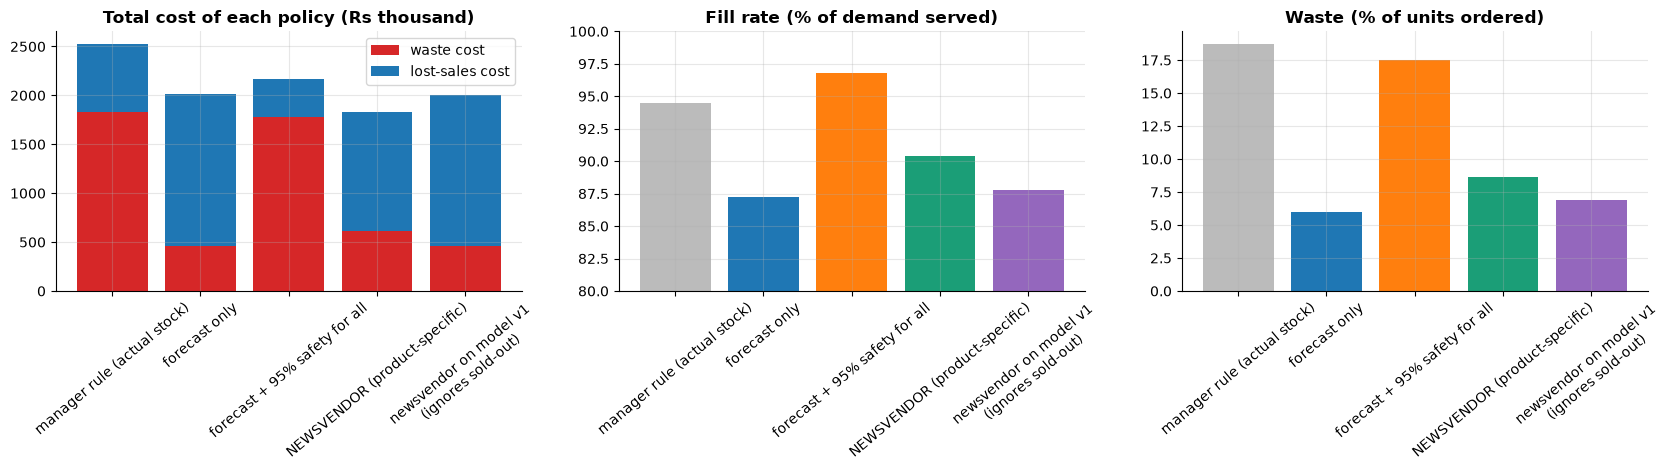

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
names = [n.split(". ")[1].replace(" (ignores sold-out days)", "\n(ignores sold-out)") for n in results.index]
cols = ["#bbbbbb", "#1f77b4", "#ff7f0e", "#1b9e77", "#9467bd"]

axes[0].bar(names, results["waste cost Rs"] / 1000, label="waste cost", color="#d62728")
axes[0].bar(names, results["lost-sales cost Rs"] / 1000, bottom=results["waste cost Rs"] / 1000, label="lost-sales cost", color="#1f77b4")
axes[0].set_title("Total cost of each policy (Rs thousand)"); axes[0].legend(); axes[0].tick_params(axis="x", rotation=40)

axes[1].bar(names, results["fill rate %"], color=cols)
axes[1].set_ylim(80, 100); axes[1].set_title("Fill rate (% of demand served)"); axes[1].tick_params(axis="x", rotation=40)

axes[2].bar(names, results["waste %"], color=cols)
axes[2].set_title("Waste (% of units ordered)"); axes[2].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
savefig(fig, "05_policy_comparison")

In [27]:
# Per product: which policy wins?
by_product = {}
for name, q in policies.items():
    tmp = []
    for sku in SKUS:
        m = (sim["sku"] == sku).to_numpy()
        tmp.append(simulate(sim[m], q[m])["TOTAL cost Rs"])
    by_product[name.split(". ")[1][:28]] = tmp
by_product = pd.DataFrame(by_product, index=SKUS).round(0)
by_product["best policy"] = by_product.idxmin(axis=1)
by_product

,manager rule (actual stock),forecast only,forecast + 95% safety for al,NEWSVENDOR (product-specific,newsvendor on model v1 (igno,best policy
BANANA,318664.0,302801.0,249546.0,265008.0,297200.0,forecast + 95% safety for al
BREAD,254738.0,185883.0,237296.0,171966.0,187557.0,NEWSVENDOR (product-specific
CURD,192340.0,147792.0,159920.0,144076.0,160388.0,NEWSVENDOR (product-specific
EGGS,444306.0,405024.0,368259.0,373326.0,412776.0,forecast + 95% safety for al
MILK,601206.0,355446.0,536445.0,349491.0,356994.0,NEWSVENDOR (product-specific
ONION,101692.0,152435.0,78950.0,84912.0,98802.0,forecast + 95% safety for al
PANEER,338463.0,233907.0,306186.0,228597.0,257475.0,NEWSVENDOR (product-specific
TOMATO,277035.0,233198.0,234426.0,217344.0,232779.0,NEWSVENDOR (product-specific


In [28]:
tot = results["TOTAL cost Rs"]
nv, nv1, m95, mgr = tot.iloc[3], tot.iloc[4], tot.iloc[2], tot.iloc[0]
print(f"newsvendor vs manager rule        : {(1 - nv / mgr) * 100:5.1f}% lower total cost")
print(f"newsvendor vs 95% safety for all  : {(1 - nv / m95) * 100:5.1f}% lower total cost")
print(f"fixing the censoring bias (v2 vs v1): {(1 - nv / nv1) * 100:5.1f}% lower total cost")
wins = (by_product["best policy"].str.startswith("NEWSVENDOR")).sum()
print(f"products where the newsvendor is the best policy: {wins} of {len(by_product)}")

newsvendor vs manager rule        :  27.4% lower total cost
newsvendor vs 95% safety for all  :  15.5% lower total cost
fixing the censoring bias (v2 vs v1):   8.4% lower total cost
products where the newsvendor is the best policy: 5 of 8


Reading the table:

- The **manager rule** wastes a lot **and** still sells out: both kinds of cost are high.
- **Forecast only** wastes little but loses many sales (we order the *average*, so we sell out on about half of the days).
- **95% for everyone** removes most stock-outs but throws away a lot, because it ignores that an expensive perishable and a cheap long-life product have different costs.
- The **newsvendor** gives the lowest total cost and wins for most products. For the products with a **high critical ratio** (banana, eggs, onion) the plain 95% rule can win: the factor for a high ratio is read from the far tail of the validation errors, which is estimated from few days and is still pulled down by the sold-out days (the forecast is better but not completely unbiased). With more history, a proper quantile model or a censored model fixes this.
- **Row 5 vs row 4** shows what the censoring problem costs in real money.

## 8.2 Why the newsvendor factor is the right one: the cost curve

For one product, we change the target coverage and compute the total cost on the test days. The best point should be near the **critical ratio**.

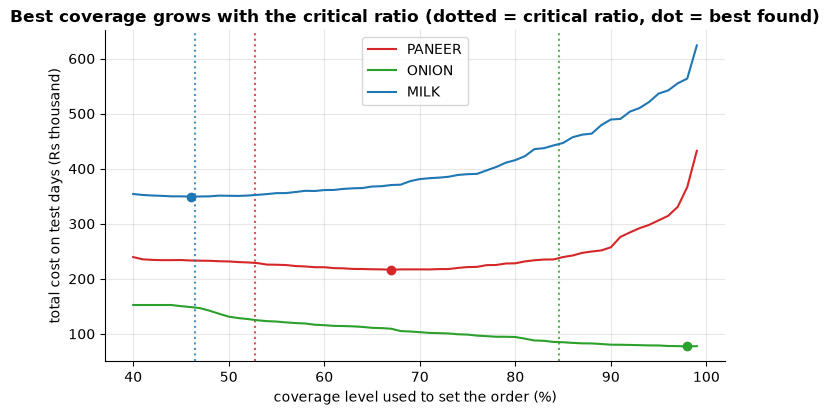

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.3))
grid_q = np.arange(0.40, 0.995, 0.01)

for sku, color in [("PANEER", "#d62728"), ("ONION", "#2ca02c"), ("MILK", "#1f77b4")]:
    m = (sim["sku"] == sku).to_numpy()
    sub = sim[m]
    cost_curve = [simulate(sub, sub["forecast"].to_numpy() * ratio_by_sku.quantile(q).loc[sku])["TOTAL cost Rs"] for q in grid_q]
    ax.plot(grid_q * 100, np.array(cost_curve) / 1000, color=color, label=sku)
    ax.axvline(costs.loc[sku, "critical_ratio"] * 100, color=color, linestyle=":", alpha=0.8)
    best_q = grid_q[int(np.argmin(cost_curve))]
    ax.plot(best_q * 100, min(cost_curve) / 1000, "o", color=color)

ax.set_xlabel("coverage level used to set the order (%)"); ax.set_ylabel("total cost on test days (Rs thousand)")
ax.set_title("Best coverage grows with the critical ratio (dotted = critical ratio, dot = best found)")
ax.legend()
plt.show()
savefig(fig, "06_cost_curve")

- The cost is lowest at a **different coverage level for each product**: milk (low critical ratio) is best near 50%, paneer higher, and onion (cheap, long shelf life, critical ratio 0.85) keeps getting cheaper as coverage rises. The **order of the products agrees with the theory** (higher critical ratio, higher best coverage).
- For paneer and onion the best points sit **to the right** of their critical ratios (dotted lines). The reason is the forecast: even after the censoring correction it is still a little low, so asking validation for "x% coverage" gives less real coverage than x%.
- The curves are **flat near the bottom**: being roughly right is enough, while large mistakes in either direction are expensive (the steep rise on the right side for milk and paneer is waste).
- A single "95% for everyone" rule is not optimal: it over-stocks expensive perishables and cannot know that onion deserves more.

**Say it in an interview:** "A forecast is not an order. I turned it into an order with the newsvendor rule: the demand quantile at underage/(underage+overage), using quantiles of the validation forecast errors, and compared four policies in rupees against the true demand."

# 9. Save the deliverables

In [30]:
orders_next = sim[sim["date"] == sim["date"].max()][["series", "date", "forecast"]].copy()
orders_next["order_qty"] = np.round(orders_next["forecast"] * orders_next["series"].str.split("|").str[1].map(cr_factor))
orders_next.round({"forecast": 0, "order_qty": 0}).head(8)

,series,date,forecast,order_qty
83,S1-Indore|BANANA,2026-06-30,137.0,144.0
167,S1-Indore|BREAD,2026-06-30,105.0,111.0
251,S1-Indore|CURD,2026-06-30,103.0,105.0
335,S1-Indore|EGGS,2026-06-30,129.0,135.0
419,S1-Indore|MILK,2026-06-30,185.0,192.0
503,S1-Indore|ONION,2026-06-30,152.0,179.0
586,S1-Indore|PANEER,2026-06-30,47.0,48.0
670,S1-Indore|TOMATO,2026-06-30,137.0,145.0


In [31]:
df.to_csv(DATA / "daily_features.csv", index=False)
results.round(2).to_csv(DATA / "policy_comparison.csv")
card = {
    "task": "forecast daily demand with a 2-day lead time, then set order quantities (newsvendor)",
    "model": "ridge regression (NumPy closed form) on log1p(units), global model with product interactions",
    "lambda": round(float(best_lam), 2), "n_features": len(feature_names),
    "split": {"train_end": str(train_end.date()), "valid_start": str(valid_start.date()), "test_start": str(test_start.date())},
    "test_metrics": {k: round(float(v), 3) for k, v in result.loc["RIDGE v2 (final)"].items()},
    "critical_ratios": costs["critical_ratio"].round(3).to_dict(),
}
(DATA / "model_card.json").write_text(json.dumps(card, indent=2))
print(json.dumps(card, indent=2)[:900])

{
  "task": "forecast daily demand with a 2-day lead time, then set order quantities (newsvendor)",
  "model": "ridge regression (NumPy closed form) on log1p(units), global model with product interactions",
  "lambda": 0.1,
  "n_features": 109,
  "split": {
    "train_end": "2026-02-10",
    "valid_start": "2026-02-11",
    "test_start": "2026-04-08"
  },
  "test_metrics": {
    "WAPE %": 14.68,
    "bias %": 2.09,
    "MAE (units)": 19.04
  },
  "critical_ratios": {
    "MILK": 0.464,
    "CURD": 0.533,
    "BREAD": 0.552,
    "EGGS": 0.645,
    "TOMATO": 0.62,
    "ONION": 0.846,
    "PANEER": 0.527,
    "BANANA": 0.662
  }
}


---
# 10. Summary, resume bullets, interview questions

In [32]:
base = results.loc["1. manager rule (actual stock)"]; best = results.loc["4. NEWSVENDOR (product-specific)"]
fm = result.loc["RIDGE v2 (final)"]; sn = result.loc["seasonal naive: same weekday last week"]
print("RESULTS (test period: 12 weeks, 24 store-product series)")
print(f"  forecast WAPE {fm['WAPE %']:.1f}% (seasonal naive {sn['WAPE %']:.1f}%), bias {fm['bias %']:.1f}%")
print(f"  manager rule: cost Rs {base['TOTAL cost Rs']:,.0f} | newsvendor: cost Rs {best['TOTAL cost Rs']:,.0f}  ({(1 - best['TOTAL cost Rs'] / base['TOTAL cost Rs']) * 100:.0f}% lower)")
print(f"  waste {base['waste %']:.1f}% -> {best['waste %']:.1f}% of units | fill rate {base['fill rate %']:.1f}% -> {best['fill rate %']:.1f}%")

print("\nRESUME BULLETS (use your own numbers)")
print(f"- Built a demand forecasting and ordering system for a 3-store supermarket chain (24 product-store series, 2 years of daily data): cleaned 4 raw files, rebuilt a complete calendar, and handled stock-out censored sales.")
print(f"- Engineered lag, rolling, calendar, festival, promotion and weather features with a 2-day order lead time and implemented ridge regression from scratch in NumPy; WAPE {fm['WAPE %']:.1f}% vs {sn['WAPE %']:.1f}% for a seasonal-naive baseline.")
print(f"- Applied the newsvendor model with product-specific critical ratios, cutting simulated waste plus lost-sales cost by {(1 - best['TOTAL cost Rs'] / base['TOTAL cost Rs']) * 100:.0f}% versus the store-manager rule.")

RESULTS (test period: 12 weeks, 24 store-product series)
  forecast WAPE 14.7% (seasonal naive 20.1%), bias 2.1%
  manager rule: cost Rs 2,528,445 | newsvendor: cost Rs 1,834,720  (27% lower)
  waste 18.7% -> 8.7% of units | fill rate 94.4% -> 90.4%

RESUME BULLETS (use your own numbers)
- Built a demand forecasting and ordering system for a 3-store supermarket chain (24 product-store series, 2 years of daily data): cleaned 4 raw files, rebuilt a complete calendar, and handled stock-out censored sales.
- Engineered lag, rolling, calendar, festival, promotion and weather features with a 2-day order lead time and implemented ridge regression from scratch in NumPy; WAPE 14.7% vs 20.1% for a seasonal-naive baseline.
- Applied the newsvendor model with product-specific critical ratios, cutting simulated waste plus lost-sales cost by 27% versus the store-manager rule.


## Likely interview questions about this project

**1. Why is "sales" not the same as "demand"?**
Sales are capped by the stock. On a sold-out day the recorded sales are only a lower bound of demand (censored data). Training on them makes the model under-forecast, which creates more stock-outs.

**2. How did you handle the censored days?**
I flagged `units_sold >= stock_start`, excluded those days from the training target and from the accuracy metrics, and mentioned censored regression (Tobit) as the proper extension.

**3. What is the order lead time doing to your features?**
The forecast for day t is made on day t - 2, so every demand feature is shifted by at least 2 days. I asserted this in code. Using yesterday's sales would be leakage.

**4. Why WAPE instead of MAPE?**
MAPE divides by each day's actual, which explodes for small values and is asymmetric. WAPE divides the total error by the total demand.

**5. Why a global model for 24 series?**
It shares information across products and stores and handles short histories. Product-specific behaviour comes from interaction features (product x weekday, promo, festival, temperature).

**6. Explain the newsvendor rule.**
The best order is the demand quantile at underage/(underage + overage). Each product has its own costs, so its own service level. A product that spoils quickly gets a lower ratio, a long-life cheap product gets a high one.

**7. How did you measure uncertainty?**
Quantiles of the validation ratio `actual / forecast` per product give the safety factors. A better version uses quantile regression or conformal prediction.

**8. Why evaluate the policies against the true demand?**
Observed sales cannot tell what would have happened with a different order quantity. The simulator gives the real demand. In a real company you run a pilot (A/B test) in some stores.

**9. How would you deploy it?**
A daily job: refresh data, build features, forecast, apply factors, write the order file. Monitor WAPE, bias, waste and fill rate by product, and retrain regularly.

**10. What would you improve next?**
Hierarchical forecasting, gradient boosting, promotions planned in advance with proper price elasticity, substitution effects, and a pilot test.

## Extension ideas

1. Replace ridge with `HistGradientBoostingRegressor` (scikit-learn) and compare WAPE.
2. Add **quantile regression** (pinball loss in NumPy) to predict the critical-ratio quantile directly.
3. Model the **censored days** properly (Tobit regression).
4. Add a **dashboard** in Streamlit (your folder `21_streamlit`) that shows the order sheet per store.
5. Serve the order recommendations with **FastAPI** (your folder `22_fast_api`).

## Revision sheet: functions you practised

| Library | Functions and ideas |
|---|---|
| **pandas** | `drop_duplicates`, `to_datetime` two-pass, `str.replace`, `map`, `rolling(center=True)`, `MultiIndex.from_product`, `merge(validate="one_to_one"/"many_to_one")`, `groupby().shift/transform/rolling`, `interpolate`, `pivot_table`, `unstack`, `idxmin`, `quantile` |
| **NumPy** | broadcasting `A[:, :, None] * B[:, None, :]`, `reshape`, `hstack`, `column_stack`, `linalg.solve`, `log1p/expm1`, `minimum/maximum`, `polyfit/polyval`, `logspace`, `argmin` |
| **Matplotlib** | `axvspan`, `imshow` + `text` heatmap, grouped bars, `boxplot`, stacked bars, `semilogx`, dotted `axvline` |
| **Forecasting ideas** | calendar rebuilding, censoring, lead time and lags, WAPE/bias, baselines, newsvendor, simulation against truth |